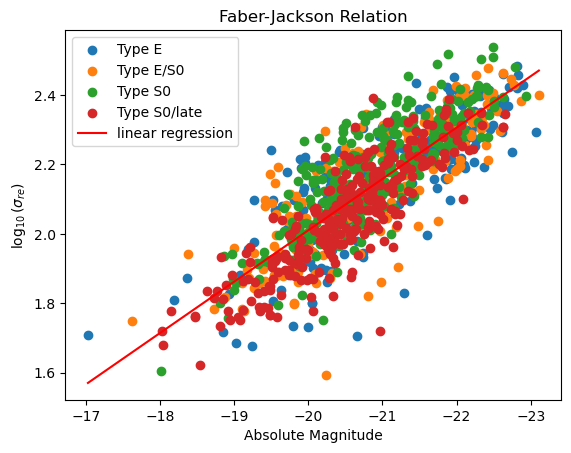

In [1]:
import numpy as np
import matplotlib.pyplot as plt

skiprow, catid, type, sigma_re, m_r = np.loadtxt('cleaned_data_mr_1.5.txt', unpack=True) # Data saved as array in text file
yvalues = np.log10(sigma_re)
xvalues = m_r   # m_r

M = xvalues
sigma = yvalues

a,b= np.polyfit(M, sigma, 1) # Fit a linear regression to the data
xcoords = np.linspace(np.min(M), np.max(M), 100) # Create an array of x values for the linear regression line
ycoords = a * xcoords + b # Calculate the y values of the linear regression line

E = type == 0.0
E_S0 = type == 0.5
S0 = type == 1.0
S0_late = type == 1.5

plt.scatter(xvalues[E], yvalues[E], label="Type E")
plt.scatter(xvalues[E_S0], yvalues[E_S0], label="Type E/S0")
plt.scatter(xvalues[S0], yvalues[S0], label="Type S0")
plt.scatter(xvalues[S0_late], yvalues[S0_late], label="Type S0/late")
plt.plot(xcoords, ycoords, color="red", label="linear regression") #show linear regression as red line


plt.gca().invert_xaxis() #invert x axis to match the convention of absolute magnitude (brighter objects have lower magnitudes)

plt.legend(loc="best")
plt.title("Faber-Jackson Relation")
plt.xlabel(r"Absolute Magnitude")
plt.ylabel(r"$\log_{10}(\sigma_{re})$")
plt.show()

In [2]:
from scipy.optimize import curve_fit

def relation(Mag, k, b):
    return k * Mag + b

params, covariance = curve_fit(relation, M, sigma)

k = params[0] 

fit = relation(M,k,b)

SS_res = np.sum((sigma - fit)**2)
SS_tot = np.sum((sigma - np.mean(sigma))**2)

R2 = 1- SS_res/SS_tot

corr_coef = np.sqrt(R2)

print("k =", k)
print("R^2 =", R2)
print("r=", corr_coef)
print("SS_res=", SS_res)
print("SS_tot=", SS_tot)

k = -0.14793570713298454
R^2 = 0.6811491804390268
r= 0.8253176239721449
SS_res= 9.874541133331979
SS_tot= 30.969157134136488


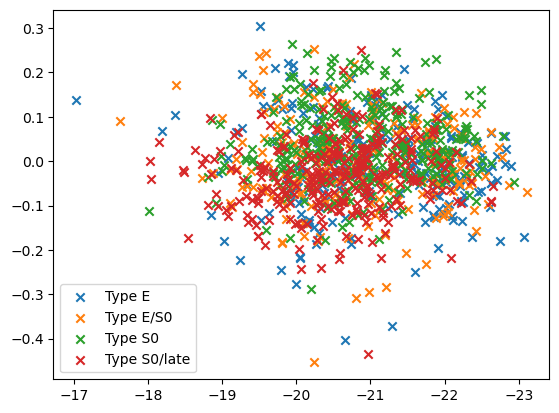

In [4]:
res = sigma - fit

plt.scatter(M[E], res[E], label="Type E", marker = 'x')
plt.scatter(M[E_S0], res[E_S0], label="Type E/S0", marker = 'x')
plt.scatter(M[S0], res[S0], label="Type S0", marker = 'x')
plt.scatter(M[S0_late], res[S0_late], label="Type S0/late", marker = 'x')
plt.gca().invert_xaxis()
plt.legend()

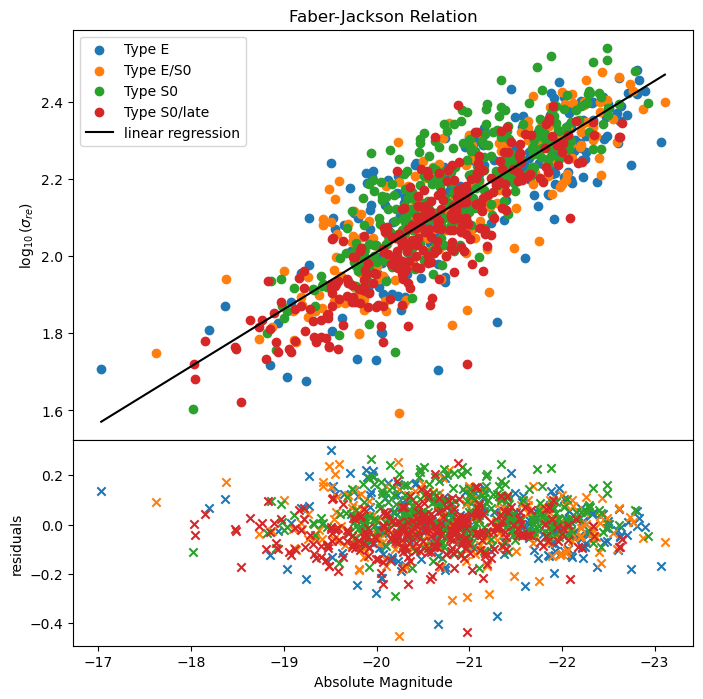

In [23]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), gridspec_kw={'height_ratios': [2, 1]})

ax1.scatter(xvalues[E], yvalues[E], label="Type E")
ax1.scatter(xvalues[E_S0], yvalues[E_S0], label="Type E/S0")
ax1.scatter(xvalues[S0], yvalues[S0], label="Type S0")
ax1.scatter(xvalues[S0_late], yvalues[S0_late], label="Type S0/late")
ax1.plot(xcoords, ycoords, color="black", label="linear regression",)

ax1.legend(loc="best")
ax1.set_title("Faber-Jackson Relation")
ax2.set_xlabel(r"Absolute Magnitude")
ax1.set_ylabel(r"$\log_{10}(\sigma_{re})$")

ax2.scatter(M[E], res[E], label="Type E", marker = 'x')
ax2.scatter(M[E_S0], res[E_S0], label="Type E/S0", marker = 'x')
ax2.scatter(M[S0], res[S0], label="Type S0", marker = 'x')
ax2.scatter(M[S0_late], res[S0_late], label="Type S0/late", marker = 'x')
ax2.set_ylabel(r"residuals")

ax1.invert_xaxis()
ax2.invert_xaxis()
plt.subplots_adjust(hspace=0)